# FlashPointHexShape: division + triangular-ring position reconstruction

This notebook extends the previous hexagon `centralSiPMDivisions` analysis to the new 2-D triangular-lattice (`ring`) central layout.

Configured production samples:

- `edge3_center6` → division reference, 37 SiPMs;
- `edge2_ring2_p207` → 37 SiPMs;
- `edge3_ring2_p207` → 43 SiPMs;
- `edge3_ring3_p140` → 61 SiPMs;
- `edge3_ring4_p105` → 85 SiPMs;
- `edge3_ring5_p84` → 115 SiPMs;
- `edge5_ring5_p84` → 127 SiPMs.

Change only `SETUP` and `RUN` in the configuration cell. The notebook keeps the same
\[
\sigma_{xy}=\sqrt{\frac{\sigma_x^2+\sigma_y^2}{2}}
\]
definition, timing treatment, ExtraTrees reconstruction, local-resolution maps, and 10-mm contour used in the previous division study.

For the high-channel samples, `RUN_FULL_ST=False` is recommended by default because the full per-SiPM \(dN/dt\) tensor can become several GB. `A+t_1+t_2+t_3` ExtraTrees remains enabled.


### Geometry / channel-order notes

The detector channel model follows the Geant4 construction:

- first 6 channels: hexagon vertices;
- next `6*NEDGE`: edge add-on SiPMs;
- remaining channels: central +Z SiPMs;
- `division` mode uses the original three vertex-to-vertex diagonals;
- `ring` mode reproduces the C++ axial-coordinate triangular lattice exactly.

The nonlinear ML methods use the ROOT channel order directly. Analytical SiPM coordinates are used for COG and geometry plots.

At the end of the notebook, a multi-setup comparison cell reads the saved reconstruction summaries and plots resolution versus total channel count.


In [13]:
# 0. Imports + configuration
from pathlib import Path
import re, warnings
from scipy import sparse
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

SEED=42

# ------------------------------------------------------------
# Production setups
# ------------------------------------------------------------
SETUPS={
    "edge3_center6":      dict(mode="division", edge=3, center=6),
    "edge2_ring2_p207":   dict(mode="ring", edge=2, rings=2, pitch=207.),
    "edge3_ring2_p207":   dict(mode="ring", edge=3, rings=2, pitch=207.),
    "edge3_ring3_p140":   dict(mode="ring", edge=3, rings=3, pitch=140.),
    "edge3_ring4_p105":   dict(mode="ring", edge=3, rings=4, pitch=105.),
    "edge3_ring5_p84":    dict(mode="ring", edge=3, rings=5, pitch=84.),
    "edge5_ring5_p84":    dict(mode="ring", edge=5, rings=5, pitch=84.),
}

# Change this line for one-sample reconstruction
SETUP="edge5_ring5_p84"
cfg=SETUPS[SETUP]

MODE=cfg["mode"]
NEDGE=cfg["edge"]
CENTER=cfg.get("center",0)
RINGS=cfg.get("rings",0)
PITCH=cfg.get("pitch",np.nan)

def division_count(n):
    if n==0: return 0
    if n<2: raise ValueError("centralSiPMDivisions must be 0 or >=2")
    return 3*(n-1)-(2 if n%2==0 else 0)

NCENTER=division_count(CENTER) if MODE=="division" else 1+3*RINGS*(RINGS+1)
EXPECTED_NSIPM=6+6*NEDGE+NCENTER
TAG=SETUP

EDGE_LENGTH=620.4
HEX_R=EDGE_LENGTH
HEX_H=np.sqrt(3)/2*HEX_R
HEX_AREA=3*np.sqrt(3)/2*HEX_R**2
EQUIV_LENGTH=np.sqrt(HEX_AREA)
HEX_EXTENT=(-HEX_R,HEX_R,-HEX_H,HEX_H)

# detector timing smearing
APPLY_TIMING_SMEARING=True
TIMING_SIGMA_PS=300

# ------------------------------------------------------------
# Production path: change only if needed
# ------------------------------------------------------------
RUN=Path("/Volumes/ExtremeSSD/Software/FlashPointHexShape/run/RingBulkPro")

INDIR=RUN/f"output_{TAG}"
OUT=RUN/f"output_{TAG}_reco"; OUT.mkdir(parents=True,exist_ok=True)
FILES=sorted(INDIR.glob("*.root"))

if not FILES:
    raise FileNotFoundError(f"No ROOT files found in {INDIR}")

# Infer actual channel count from ROOT and verify the geometry request.
with uproot.open(FILES[0]) as f:
    if "events" not in f:
        raise KeyError(f"{FILES[0]} has no 'events' tree")
    amp_ids=sorted(int(m.group(1)) for k in f["events"].keys()
                   if (m:=re.fullmatch(r"n_detected_sipm(\d+)",str(k))))

if not amp_ids or amp_ids!=list(range(max(amp_ids)+1)):
    raise ValueError("n_detected_sipmN branches are missing or non-contiguous")

NSIPM=len(amp_ids)
if NSIPM!=EXPECTED_NSIPM:
    raise ValueError(
        f"{TAG}: expected {EXPECTED_NSIPM} SiPMs but ROOT contains {NSIPM}. "
        "Check the production configuration."
    )

TRAIN_FRAC=.70

# spatial response templates
GRID_NX=max(2,int(round(2*HEX_R/25)))
GRID_NY=max(2,int(round(2*HEX_H/25)))
MIN_CELL=10
POSTERIOR_K=9
LIKELIHOOD_CHUNK=2000
FEATURE_CHUNK=2000
HIST_DTYPE=np.uint16

# timing histogram settings (only allocated when RUN_FULL_ST=True)
DT_FINE_NS=.05
EARLY_NS=3.0
DND_REBIN=2
NBIN_FINE=int(round(EARLY_NS/DT_FINE_NS))

# nonlinear regression
HGB_MAX_ITER=180
HGB_LEAVES=31
ML_TRAIN_MAX=100_000

# expensive/optional studies
RUN_EXTRA_TREES=True
RUN_FULL_ST=False
RUN_TIMING_BIN_SCAN=False
RUN_TRUE_TIMING_SCAN=False
SIGMA_T_PS=[0,50,100,150,200,250,300,400,500,750,1000]
NEED_DND=RUN_FULL_ST or RUN_TIMING_BIN_SCAN

if not (0<TRAIN_FRAC<1) or MIN_CELL<1:
    raise ValueError("Invalid split/grid settings")
if TIMING_SIGMA_PS<0 or POSTERIOR_K<1:
    raise ValueError("Invalid timing/interpolation settings")

print(f"{TAG}: mode={MODE}, NSIPM={NSIPM} = 6 vertex + {6*NEDGE} edge + {NCENTER} center")
if MODE=="division":
    print(f"centralSiPMDivisions={CENTER}")
else:
    print(f"centralSiPMRings={RINGS}, pitch={PITCH:g} mm")
print(f"Hexagon: R={HEX_R:.1f} mm, H={HEX_H:.3f} mm, area={HEX_AREA/1e6:.6f} m^2")
print(f"ROOT files={len(FILES)} from {INDIR}")
print(f"Timing smearing: {APPLY_TIMING_SMEARING}, sigma={TIMING_SIGMA_PS} ps")
print(f"Full dN/dt/ST analysis: {RUN_FULL_ST}")


edge5_ring5_p84: mode=ring, NSIPM=127 = 6 vertex + 30 edge + 91 center
centralSiPMRings=5, pitch=84 mm
Hexagon: R=620.4 mm, H=537.282 mm, area=0.999990 m^2
ROOT files=20 from /Volumes/ExtremeSSD/Software/FlashPointHexShape/run/RingBulkPro/output_edge5_ring5_p84
Timing smearing: True, sigma=300 ps
Full dN/dt/ST analysis: False


SiPM   0 [V]: (  620.400,    0.000) mm
SiPM   1 [V]: (  310.200,  537.282) mm
SiPM   2 [V]: ( -310.200,  537.282) mm
SiPM   3 [V]: ( -620.400,    0.000) mm
SiPM   4 [V]: ( -310.200, -537.282) mm
SiPM   5 [V]: (  310.200, -537.282) mm
SiPM   6 [E]: (  568.700,   89.547) mm
SiPM   7 [E]: (  517.000,  179.094) mm
SiPM   8 [E]: (  465.300,  268.641) mm
SiPM   9 [E]: (  413.600,  358.188) mm
SiPM  10 [E]: (  361.900,  447.735) mm
SiPM  11 [E]: (  206.800,  537.282) mm
SiPM  12 [E]: (  103.400,  537.282) mm
SiPM  13 [E]: (    0.000,  537.282) mm
SiPM  14 [E]: ( -103.400,  537.282) mm
SiPM  15 [E]: ( -206.800,  537.282) mm
SiPM  16 [E]: ( -361.900,  447.735) mm
SiPM  17 [E]: ( -413.600,  358.188) mm
SiPM  18 [E]: ( -465.300,  268.641) mm
SiPM  19 [E]: ( -517.000,  179.094) mm
SiPM  20 [E]: ( -568.700,   89.547) mm
SiPM  21 [E]: ( -568.700,  -89.547) mm
SiPM  22 [E]: ( -517.000, -179.094) mm
SiPM  23 [E]: ( -465.300, -268.641) mm
SiPM  24 [E]: ( -413.600, -358.188) mm
SiPM  25 [E]: ( -361.900,

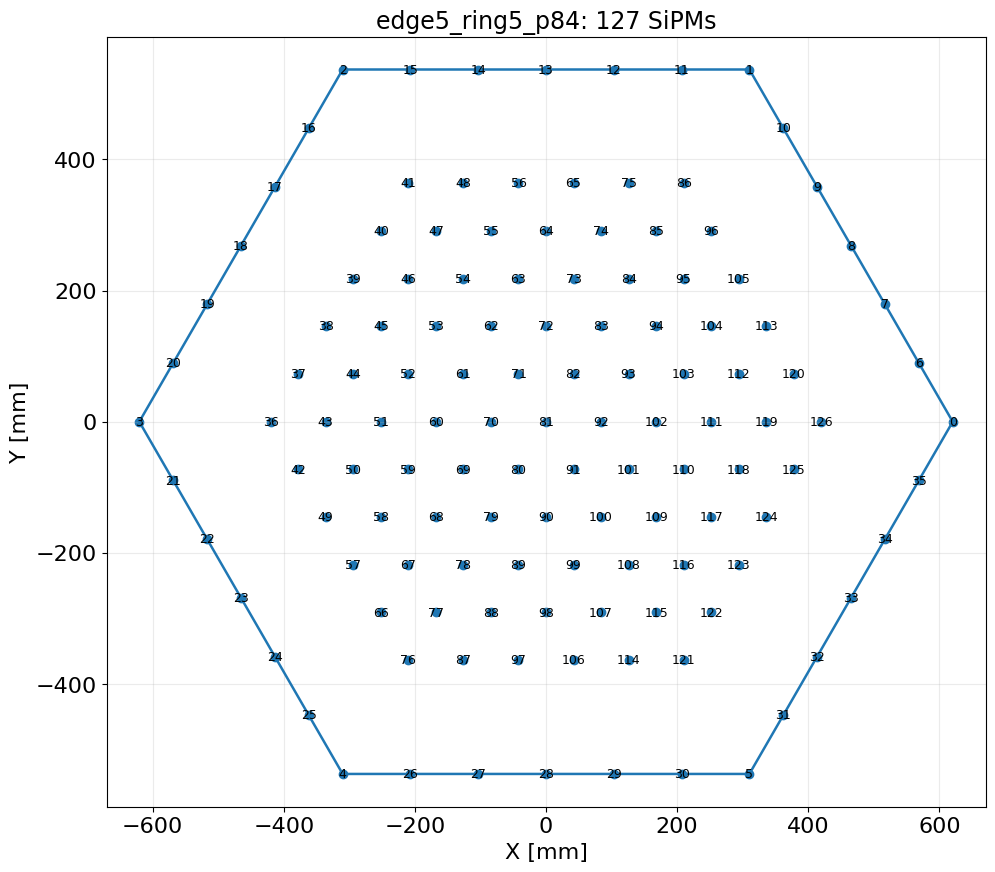

In [14]:
# 1. Hexagonal detector geometry + analytical SiPM XY positions
def hex_vertices(r=HEX_R):
    a=np.deg2rad(np.arange(0,360,60))
    return np.column_stack([r*np.cos(a),r*np.sin(a)])

VERT=hex_vertices()

def inside_hex(x,y,eps=1e-9):
    x,y=np.asarray(x),np.asarray(y)
    return (np.abs(y)<=HEX_H+eps)&(np.abs(x)<=HEX_R-np.abs(y)/np.sqrt(3)+eps)

def division_positions(divisions):
    if divisions==0: return np.empty((0,2),float)
    pts=[]
    for j in range(3):
        a,b=VERT[j+3],VERT[j]
        for k in range(1,divisions):
            p=a+(b-a)*(k/divisions)
            if not any(np.allclose(p,q,atol=1e-9) for q in pts):
                pts.append(p)
    return np.asarray(pts,float)

def ring_positions(rings,pitch):
    # Exact Python equivalent of MakeCentralRingPositions(q,r) in DetectorConstruction.
    pts=[]
    for q in range(-rings,rings+1):
        rmin=max(-rings,-q-rings)
        rmax=min( rings,-q+rings)
        for r in range(rmin,rmax+1):
            x=pitch*(q+0.5*r)
            y=pitch*np.sqrt(3)/2*r
            pts.append((x,y))
    return np.asarray(pts,float)

def get_POS():
    pos=list(VERT)
    for j in range(6):
        a,b=VERT[j],VERT[(j+1)%6]
        for k in range(1,NEDGE+1):
            pos.append(a+(b-a)*(k/(NEDGE+1)))
    center=(division_positions(CENTER) if MODE=="division"
            else ring_positions(RINGS,PITCH))
    pos.extend(center)
    return np.asarray(pos,float)

POS=get_POS()
assert len(POS)==NSIPM, (len(POS),NSIPM)
assert inside_hex(POS[:,0],POS[:,1]).all(), "At least one analytical SiPM XY point is outside the hexagon"

def draw_hex(ax,lw=1.8,ls="-"):
    p=np.vstack([VERT,VERT[0]])
    ax.plot(p[:,0],p[:,1],ls=ls,lw=lw)

for i,(x,y) in enumerate(POS):
    kind="V" if i<6 else ("E" if i<6+6*NEDGE else "C")
    print(f"SiPM {i:3d} [{kind}]: ({x:9.3f},{y:9.3f}) mm")

fig,ax=plt.subplots(figsize=(12,10))
draw_hex(ax)
ax.scatter(POS[:,0],POS[:,1])
for i,(x,y) in enumerate(POS):
    ax.text(x,y,str(i),ha="center",va="center",fontsize=9 if NSIPM>60 else 12)
ax.set(xlabel="X [mm]",ylabel="Y [mm]",aspect="equal",
       xlim=(-HEX_R-50,HEX_R+50),ylim=(-HEX_H-50,HEX_H+50),
       title=f"{TAG}: {NSIPM} SiPMs")
ax.tick_params(labelsize=16)
ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16); ax.title.set_size(17)
ax.grid(alpha=.25)
plt.show()


## 2. Load ROOT files and build timing features

To avoid keeping the full `hits` tree from every batch job in memory, each file is processed separately.

For each event and SiPM the notebook derives:

- detected photon count $N_i$;
- $t_{i,1},t_{i,2},t_{i,3}$, each relative to the earliest detected photon in the event;
- an early-photon $dN_i/dt$ histogram.

The event ordering of the timing arrays is kept exactly aligned with the concatenated `events` DataFrame.


In [115]:
# 2. Load events + derive T1/T2/T3; dN/dt is optional
TIME_NAMES=["t_plot_ns","t_ns","time_ns","arrival_time_ns","global_time_ns"]

def integer_ids(values,label):
    values=np.asarray(values)
    if not np.isfinite(values).all() or not np.equal(values,np.floor(values)).all():
        raise ValueError(f"{label} must contain finite integer IDs")
    return values.astype(np.int64)

def read_hit_arrays(f,local):
    if len(np.unique(local))!=len(local):
        raise ValueError("Duplicate local event IDs; hit-to-event mapping is ambiguous")
    if "hits" not in f:
        raise KeyError("Missing hits tree: timing studies require complete hit information")
    tree=f["hits"]
    thit=next((x for x in TIME_NAMES if x in tree.keys()),None)
    if thit is None:
        raise KeyError(f"No timing branch found; tried {TIME_NAMES}")
    h=tree.arrays(["event","sipm",thit],library="np")
    ev=integer_ids(h["event"],"hits.event")
    sipm=integer_ids(h["sipm"],"hits.sipm")
    tm=np.asarray(h[thit],dtype=np.float64)
    row=pd.Index(local).get_indexer(ev)
    if (row<0).any() or ((sipm<0)|(sipm>=NSIPM)).any() or not np.isfinite(tm).all():
        raise ValueError("Unmapped event, out-of-range SiPM or nonfinite hit time")
    return row,sipm,tm

def timing_features(row,sipm,tm,n,sigma_ps,rg,with_dnd=False):
    tm=tm.copy()
    if sigma_ps:
        tm+=rg.normal(0,sigma_ps/1000.,len(tm))
    t0=np.full(n,np.inf)
    np.minimum.at(t0,row,tm)
    dt=tm-t0[row]
    group=row*NSIPM+sipm
    order=np.lexsort((tm,group))
    gs=group[order]
    starts=np.flatnonzero(np.r_[True,gs[1:]!=gs[:-1]]) if len(gs) else np.empty(0,int)
    ends=np.r_[starts[1:],len(gs)]

    times=[]
    for k in range(3):
        target=np.full((n,NSIPM),np.nan,np.float32)
        take=starts[starts+k<ends]+k
        target.ravel()[gs[take]]=dt[order[take]]
        times.append(target)

    if not with_dnd:
        return (*times,None)

    dnd=np.zeros((n,NSIPM,NBIN_FINE),dtype=HIST_DTYPE)
    early=dt<EARLY_NS
    b=np.floor(dt[early]/DT_FINE_NS).astype(np.int64)
    inside=(b>=0)&(b<NBIN_FINE)
    flat=group[early][inside]*NBIN_FINE+b[inside]
    occupied,count=np.unique(flat,return_counts=True)
    if len(count) and count.max()>np.iinfo(HIST_DTYPE).max:
        raise OverflowError("Histogram overflow: set HIST_DTYPE=np.uint32")
    dnd.ravel()[occupied]=count
    return (*times,dnd)

file_sizes=[]
for fname in FILES:
    with uproot.open(fname) as f:
        file_sizes.append(int(f["events"].num_entries))

ntotal=sum(file_sizes)
T1=np.full((ntotal,NSIPM),np.nan,np.float32)
T2=np.full_like(T1,np.nan)
T3=np.full_like(T1,np.nan)
DND_FINE=(np.zeros((ntotal,NSIPM,NBIN_FINE),dtype=HIST_DTYPE) if NEED_DND else None)

E=[]; offset=0
rng_smear=np.random.default_rng(SEED+100)

for job,(fname,n) in enumerate(zip(FILES,file_sizes)):
    with uproot.open(fname) as f:
        e=pd.DataFrame(f["events"].arrays(library="np"))
        if len(e)!=n:
            raise ValueError(f"Event row count changed in {fname}")
        local=integer_ids(e["event"] if "event" in e else np.arange(n),"events.event")
        row,sipm,tm=read_hit_arrays(f,local)
        amplitude=e[[f"n_detected_sipm{i}" for i in range(NSIPM)]].to_numpy(float)
        hit_count=np.bincount(row*NSIPM+sipm,minlength=n*NSIPM).reshape(n,NSIPM)

        if not np.array_equal(amplitude,hit_count):
            raise ValueError(f"{fname.name}: hit counts disagree with amplitude branches")

        t1,t2,t3,dnd=timing_features(
            row,sipm,tm,n,
            TIMING_SIGMA_PS if APPLY_TIMING_SMEARING else 0,
            rng_smear,with_dnd=NEED_DND)

        sl=slice(offset,offset+n)
        T1[sl]=t1; T2[sl]=t2; T3[sl]=t3
        if NEED_DND:
            DND_FINE[sl]=dnd

        e["event_local"]=local
        e["job"]=job
        e["event"]=np.arange(offset,offset+n)
        E.append(e); offset+=n
        print(f"{job:3d} {fname.name:42s} events={n:6d}")
        del row,sipm,tm,hit_count,amplitude,t1,t2,t3,dnd

events=pd.concat(E,ignore_index=True).replace([np.inf,-np.inf],np.nan)
del E,e

assert len(events)==len(T1)
if NEED_DND:
    assert len(events)==len(DND_FINE)

print("\nTotal events:",len(events))
print("T1/T2/T3 shape:",T1.shape)
if NEED_DND:
    print("DND_FINE shape:",DND_FINE.shape,f"({DND_FINE.nbytes/1024**3:.2f} GiB)")
else:
    print("DND_FINE skipped (RUN_FULL_ST=False)")


  0 sipm_edge5_ring5_p84_0.root                events= 10000
  1 sipm_edge5_ring5_p84_1.root                events= 10000
  2 sipm_edge5_ring5_p84_10.root               events= 10000
  3 sipm_edge5_ring5_p84_11.root               events= 10000
  4 sipm_edge5_ring5_p84_12.root               events= 10000
  5 sipm_edge5_ring5_p84_13.root               events= 10000
  6 sipm_edge5_ring5_p84_14.root               events= 10000
  7 sipm_edge5_ring5_p84_15.root               events= 10000
  8 sipm_edge5_ring5_p84_16.root               events= 10000
  9 sipm_edge5_ring5_p84_17.root               events= 10000
 10 sipm_edge5_ring5_p84_18.root               events= 10000
 11 sipm_edge5_ring5_p84_19.root               events= 10000
 12 sipm_edge5_ring5_p84_2.root                events= 10000
 13 sipm_edge5_ring5_p84_3.root                events= 10000
 14 sipm_edge5_ring5_p84_4.root                events= 10000
 15 sipm_edge5_ring5_p84_5.root                events= 10000
 16 sipm_edge5_ring5_p84

In [116]:
# 3. Standardize truth + amplitude arrays
def first(df,names): return next((x for x in names if x in df),None)

X=first(events,["source_x_mm","x_source_mm","source_x","x_true_mm"])
Y=first(events,["source_y_mm","y_source_mm","source_y","y_true_mm"])
if X is None or Y is None:
    raise KeyError("Truth X/Y branches not found.")

truth=events[[X,Y]].to_numpy(float)
A=np.column_stack([events[f"n_detected_sipm{i}"].to_numpy(float) for i in range(NSIPM)])

if not np.isfinite(A).all() or (A<0).any() or not np.equal(A,np.floor(A)).all():
    raise ValueError("Amplitude branches must contain finite nonnegative integer counts")

Ntot=A.sum(1)
F=A/np.where(Ntot[:,None]>0,Ntot[:,None],np.nan)
logN=np.log1p(Ntot)[:,None]

inside=inside_hex(truth[:,0],truth[:,1])
good=np.isfinite(truth).all(1)&(Ntot>0)&inside
print("Excluded invalid/zero-photon/outside-hex events:",int((~good).sum()))

events=events.loc[good].reset_index(drop=True)
truth=truth[good]; A=A[good]; F=F[good]; logN=logN[good]
if not good.all():
    T1=T1[good]; T2=T2[good]; T3=T3[good]
    if DND_FINE is not None: DND_FINE=DND_FINE[good]
Ntot=Ntot[good]

print("Usable events:",len(truth))
print("Mean detected photons/event:",Ntot.mean())
print("Mean vertex-only photons/event:",A[:,:6].sum(1).mean())


Excluded invalid/zero-photon/outside-hex events: 0
Usable events: 200000
Mean detected photons/event: 863.590545
Mean vertex-only photons/event: 56.757935


In [117]:
# 4. Rebin early dN/dt + train/test split
def rebin_dnd(dnd,factor):
    if not isinstance(factor,(int,np.integer)) or factor<1 or dnd.shape[2]%factor:
        raise ValueError("Rebin factor must be positive and divide the full time window")
    if factor==1: return dnd
    # Bound the wide-accumulator temporary; store the final result as uint32.
    shape=(*dnd.shape[:2],dnd.shape[2]//factor)
    result=np.empty(shape,dtype=np.uint32)
    for s in range(0,len(dnd),FEATURE_CHUNK):
        block=dnd[s:s+FEATURE_CHUNK]
        reduced=block.reshape(len(block),shape[1],shape[2],factor).sum(3,dtype=np.uint64)
        if reduced.size and reduced.max()>np.iinfo(np.uint32).max:
            raise OverflowError("Rebinned histogram exceeds uint32")
        result[s:s+len(block)]=reduced
    return result

if NEED_DND:
    DND=rebin_dnd(DND_FINE,DND_REBIN)
    DT_MAIN_NS=DT_FINE_NS*DND_REBIN
    NBIN=DND.shape[2]
else:
    DND=None
    DT_MAIN_NS=DT_FINE_NS*DND_REBIN
    NBIN=None

rng=np.random.default_rng(SEED)  # rerunning this cell reproduces the split
idx=rng.permutation(len(truth))
ntr=int(TRAIN_FRAC*len(idx))
if ntr<2 or ntr>=len(idx):
    raise ValueError("Need at least two training events and one test event")
itr,ite=idx[:ntr],idx[ntr:]

# optional cap for nonlinear regressors; likelihood still uses full train sample
itr_ml=itr if len(itr)<=ML_TRAIN_MAX else rng.choice(itr,ML_TRAIN_MAX,replace=False)

print(f"train={len(itr):,}, test={len(ite):,}, ML train={len(itr_ml):,}")
print(f"Main dN/dt: {NBIN} bins/SiPM, {DT_MAIN_NS*1e3:.0f} ps/bin" if NEED_DND else "Main dN/dt: skipped")


train=140,000, test=60,000, ML train=100,000
Main dN/dt: skipped


In [118]:
# 5. Common metrics + plotting helpers
def metrics(name,xy):
    xy=np.asarray(xy)
    if xy.shape!=(len(ite),2):
        raise ValueError("Predictions must align with the held-out event rows")
    m=np.isfinite(xy).all(1)
    if not m.any():
        return dict(method=name,N=0,coverage=0.,**{k:np.nan for k in
            ("bias_x_mm","bias_y_mm","sigma_x_mm","sigma_y_mm","sigma_xy_mm",
             "RMSE_xy_mm","R68_mm","R90_mm")})
    d=xy[m]-truth[ite][m]
    dx,dy=d[:,0],d[:,1]
    r=np.hypot(dx,dy)
    sx,sy=np.std(dx),np.std(dy)
    return dict(
        method=name,N=m.sum(),coverage=m.mean(),RMSE_xy_mm=np.sqrt(np.mean(d*d)),
        bias_x_mm=dx.mean(),bias_y_mm=dy.mean(),
        sigma_x_mm=sx,sigma_y_mm=sy,
        sigma_xy_mm=np.sqrt((sx*sx+sy*sy)/2),
        R68_mm=np.quantile(r,.68),R90_mm=np.quantile(r,.90)
    )

def performance(name,xy,bins=60):
    xt,yt=truth[ite].T; xr,yr=xy.T
    m=np.isfinite(xr)&np.isfinite(yr)
    if not m.any():
        warnings.warn(f"No finite predictions for {name}"); return

    xt,yt,xr,yr=xt[m],yt[m],xr[m],yr[m]
    dx,dy=xr-xt,yr-yt; rr=np.hypot(dx,dy)

    fig,ax=plt.subplots(2,2,figsize=(15,12))
    ranges=[(-HEX_R,HEX_R),(-HEX_H,HEX_H)]

    for a,t,r,l,lim in [(ax[0,0],xt,xr,"X",ranges[0]),(ax[0,1],yt,yr,"Y",ranges[1])]:
        h=a.hist2d(t,r,bins=bins,range=[lim,lim])
        a.plot(lim,lim,"--",lw=1)
        a.set(xlabel=f"Truth {l} [mm]",ylabel=f"Reco {l} [mm]")
        c=plt.colorbar(h[3],ax=a,label="Events / bin")
        c.ax.tick_params(labelsize=16); c.set_label("Events / bin",fontsize=16)

    lim=max(HEX_R,HEX_H)
    ax[1,0].hist(dx,100,(-lim,lim),histtype="step",density=True,linewidth=2,
                 label=fr"X $\sigma$={np.std(dx):.1f} mm")
    ax[1,0].hist(dy,100,(-lim,lim),histtype="step",density=True,linewidth=2,
                 label=fr"Y $\sigma$={np.std(dy):.1f} mm")
    ax[1,0].set(xlabel="Reco - truth [mm]",ylabel="Density")
    ax[1,0].legend(fontsize=16)

    rs=np.sort(rr)
    ax[1,1].plot(rs,np.arange(1,len(rs)+1)/len(rs),linewidth=2)
    ax[1,1].axhline(.68,ls="--"); ax[1,1].axhline(.90,ls="--",linewidth=2)
    ax[1,1].set(xlabel="Radial error [mm]",ylabel="CDF",
                title=f"R68={np.quantile(rr,.68):.1f}, R90={np.quantile(rr,.90):.1f} mm")

    for a in ax.flat:
        a.tick_params(labelsize=16)
        a.xaxis.label.set_size(16); a.yaxis.label.set_size(16)
        a.title.set_size(16)

    fig.suptitle(name,fontsize=16)
    plt.tight_layout(); plt.show()


In [119]:
# 6. Conventional COG baselines
pred={}

def cog(Ax,pos):
    s=Ax.sum(1)
    out=np.full((len(Ax),2),np.nan)
    m=s>0
    out[m]=Ax[m]@pos/s[m,None]
    return out

pred["COG vertices only"]=cog(A[ite,:6],POS[:6])
pred["COG all SiPMs"]=cog(A[ite],POS)

pd.DataFrame([metrics(k,v) for k,v in pred.items()]).round(2)


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,COG vertices only,60000,1.0,189.17,-0.45,0.22,189.17,189.17,189.17,296.00,375.84
1,COG all SiPMs,60000,1.0,188.10,-0.03,0.63,188.42,187.78,188.10,317.29,379.21


## Step 1 — Full amplitude template likelihood

For each \((x,y)\) calibration cell, estimate the expected detected-photon vector

$$
\boldsymbol{\mu}(x,y)=
(\mu_0,\ldots,\mu_{N_{\rm SiPM}-1}).
$$

Assuming independent Poisson counts,

$$
-\ln L_A(x,y)
=
\sum_i
\left[
\mu_i(x,y)-N_i\ln\mu_i(x,y)
\right]
+\mathrm{const}.
$$

The final position is a likelihood-weighted interpolation of the best-scoring template cells (which need not be spatially adjacent), rather than simply returning the nearest grid center.


In [120]:
# 7. Regular hexagon-aware template builder + fast Poisson reconstruction
X_EDGES=np.linspace(-HEX_R,HEX_R,GRID_NX+1)
Y_EDGES=np.linspace(-HEX_H,HEX_H,GRID_NY+1)
X_CENTERS=(X_EDGES[:-1]+X_EDGES[1:])/2
Y_CENTERS=(Y_EDGES[:-1]+Y_EDGES[1:])/2
NCELL=GRID_NX*GRID_NY

def grid_ids(xy):
    xy=np.asarray(xy)
    if not np.isfinite(xy).all() or not inside_hex(xy[:,0],xy[:,1]).all():
        raise ValueError("Template/map coordinates must be finite and inside the hexagon")
    ix=np.clip(np.searchsorted(X_EDGES,xy[:,0],side="right")-1,0,GRID_NX-1)
    iy=np.clip(np.searchsorted(Y_EDGES,xy[:,1],side="right")-1,0,GRID_NY-1)
    return iy*GRID_NX+ix

def build_templates(X,indices=None):
    indices=itr if indices is None else np.asarray(indices)
    gid=grid_ids(truth[indices])
    count=np.bincount(gid,minlength=NCELL)
    sums=np.zeros((NCELL,X.shape[1]),float)
    for s in range(0,len(indices),FEATURE_CHUNK):
        ids=indices[s:s+FEATURE_CHUNK]
        membership=sparse.csr_matrix(
            (np.ones(len(ids)),(gid[s:s+len(ids)],np.arange(len(ids)))),
            shape=(NCELL,len(ids))
        )
        part=membership@X[ids]
        sums+=part.toarray() if sparse.issparse(part) else part

    mu=np.divide(sums,count[:,None],out=np.full_like(sums,np.nan),where=count[:,None]>0)
    gy,gx=np.divmod(np.arange(NCELL),GRID_NX)
    pos=np.column_stack([X_CENTERS[gx],Y_CENTERS[gy]])
    valid=(count>=MIN_CELL)&inside_hex(pos[:,0],pos[:,1])

    if not valid.any():
        raise ValueError("No calibrated cells: lower grid resolution/MIN_CELL or add training data")

    return (pos[valid],mu[valid],
            count.reshape(GRID_NY,GRID_NX),
            mu.reshape(GRID_NY,GRID_NX,-1))

def poisson_reco(Xq,pos,mu,k=POSTERIOR_K,chunk=LIKELIHOOD_CHUNK):
    if len(pos)==0 or k<1 or chunk<1 or Xq.shape[1]!=mu.shape[1]:
        raise ValueError("Invalid templates, feature dimensions, k or chunk")
    if not np.isfinite(mu).all() or (mu<0).any():
        raise ValueError("Poisson templates must be finite and nonnegative")
    mu=np.clip(mu,1e-6,None)
    logmu=np.ascontiguousarray(np.log(mu).T)
    musum=mu.sum(1)
    out=np.empty((Xq.shape[0],2),float)
    for s in range(0,Xq.shape[0],chunk):
        q=Xq[s:s+chunk].astype(np.float64,copy=False)
        values=q.data if sparse.issparse(q) else q
        if not np.isfinite(values).all() or (values<0).any():
            raise ValueError("Poisson observations must be finite and nonnegative")
        score=musum[None,:]-q@logmu
        kk=min(k,score.shape[1])
        ii=np.argpartition(score,kk-1,axis=1)[:,:kk]
        ss=np.take_along_axis(score,ii,axis=1)
        ss-=ss.min(1,keepdims=True)
        w=np.exp(-ss)
        out[s:s+q.shape[0]]=(w[:,:,None]*pos[ii]).sum(1)/w.sum(1)[:,None]
    return out

posA,muA,countA,muAgrid=build_templates(A)
pred["Amplitude Poisson template"]=poisson_reco(A[ite],posA,muA)
print("Amplitude template cells:",len(posA))
pd.DataFrame([metrics("Amplitude Poisson template",pred["Amplitude Poisson template"])]).round(2)


Amplitude template cells: 1614


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Amplitude Poisson template,60000,1.0,14.82,0.04,-0.03,14.73,14.91,14.82,17.15,28.33


## Steps 2–4 — Direct nonlinear regression

These stages use the same nonlinear regressor so the comparison mainly reflects the **added detector information**, not a change of algorithm:

$$
A
\rightarrow
A+t_1
\rightarrow
A+t_1+t_2+t_3
\rightarrow
A+dN/dt.
$$

Amplitude features use normalized channel fractions plus $\log(1+N_{\rm tot})$.


In [121]:
# 8. Nonlinear regression helper: materialize one feature set at a time
Afeat=np.hstack([F,logN]).astype(np.float32)

def regression_features(indices,kind):
    parts=[Afeat[indices]]
    if kind=="t1": parts += [T1[indices]]
    elif kind=="t123": parts += [T1[indices],T2[indices],T3[indices]]
    elif kind=="dnd":
        if DND is None: raise RuntimeError("dN/dt features require RUN_FULL_ST=True")
        parts += [np.log1p(DND[indices].reshape(len(indices),-1).astype(np.float32))]
    elif kind!="amplitude": raise ValueError(kind)
    return np.hstack(parts)

def hgb_xy(kind):
    Xtr=regression_features(itr_ml,kind)
    models=[]; out=np.empty((len(ite),2))
    for j in range(2):
        m=HistGradientBoostingRegressor(
            max_iter=HGB_MAX_ITER,learning_rate=.08,max_leaf_nodes=HGB_LEAVES,
            l2_regularization=1.0,random_state=SEED+j)
        m.fit(Xtr,truth[itr_ml,j])
        models.append(m)
    for s in range(0,len(ite),FEATURE_CHUNK):
        ids=ite[s:s+FEATURE_CHUNK]
        Xq=regression_features(ids,kind)
        for j,m in enumerate(models): out[s:s+len(ids),j]=m.predict(Xq)
    return out,models

hgb_stages=[("A HGB","amplitude"),("A + t1 HGB","t1"),
            ("A + t1+t2+t3 HGB","t123")]
if NEED_DND:
    hgb_stages.append((f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB","dnd"))
for name,kind in hgb_stages:
    pred[name],models=hgb_xy(kind)
    del models
pd.DataFrame([metrics(name,pred[name]) for name,_ in hgb_stages]).round(2)

,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A HGB,60000,1.0,31.15,0.10,-0.26,30.68,31.60,31.15,40.62,64.96
1,A + t1 HGB,60000,1.0,26.12,0.13,-0.26,25.65,26.59,26.12,37.61,56.03
2,A + t1+t2+t3 HGB,60000,1.0,25.11,0.06,-0.16,24.59,25.61,25.11,36.17,53.71


## Step 5 — Full binned spatiotemporal Poisson likelihood

For each SiPM, photons in the first `EARLY_NS` are retained in time bins. All later photons are collected into one additional late-photon count.

Thus every event is represented by

$$
K=
\{N_{i,b}^{\rm early},\,N_i^{\rm late}\}.
$$

For a template location \((x,y)\),

$$
-\ln L_{\rm ST}(x,y)
=
\sum_k
\left[
\lambda_k(x,y)-K_k\ln\lambda_k(x,y)
\right]
+\mathrm{const}.
$$

This is the most direct binned approximation in this notebook to a full photon-by-photon space-time likelihood.


In [122]:
# 9. Full spatiotemporal likelihood, stored as sparse counts
def spatiotemporal_counts(dnd,amplitude):
    blocks=[]
    for s in range(0,len(dnd),FEATURE_CHUNK):
        d=dnd[s:s+FEATURE_CHUNK]
        late=amplitude[s:s+len(d)]-d.sum(2,dtype=np.float64)
        if not np.isfinite(late).all() or (late<0).any():
            raise ValueError("Early counts exceed amplitude; check hit selection and count overflow")
        blocks.append(sparse.hstack([
            sparse.csr_matrix(d.reshape(len(d),-1),dtype=np.float64),
            sparse.csr_matrix(late)],format="csr"))
    return sparse.vstack(blocks,format="csr")


if RUN_FULL_ST:
    K=spatiotemporal_counts(DND,A)
    posST,muST,countST,muSTgrid=build_templates(K)
    key=f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"
    pred[key]=poisson_reco(K[ite],posST,muST)
    print("Spatiotemporal template cells:",len(posST))
    print("ST count density:",f"{K.nnz/(K.shape[0]*K.shape[1]):.2%}")
    del K
    display(pd.DataFrame([metrics(key,pred[key])]).round(2))
else:
    print("RUN_FULL_ST=False -> full spatiotemporal likelihood skipped")


RUN_FULL_ST=False -> full spatiotemporal likelihood skipped


## Step 6 — Optional ExtraTrees baseline

This is deliberately optional because it can be substantially slower and more memory hungry. It uses the compact \(A+t_1+t_2+t_3\) feature set.


In [123]:
# 10. Optional ExtraTrees (controlled only in configuration)
def training_medians(X):
    med=np.zeros(X.shape[1],dtype=X.dtype)
    finite_columns=np.isfinite(X).any(0)
    med[finite_columns]=np.nanmedian(X[:,finite_columns],axis=0)
    return med

if RUN_EXTRA_TREES:
    Xtr=regression_features(itr_ml,"t123")
    med=training_medians(Xtr)
    Xtr=np.where(np.isfinite(Xtr),Xtr,med)
    model=ExtraTreesRegressor(n_estimators=300,min_samples_leaf=2,
        max_features=.8,n_jobs=-1,random_state=SEED)
    model.fit(Xtr,truth[itr_ml])
    del Xtr
    xy=np.empty((len(ite),2))
    for s in range(0,len(ite),FEATURE_CHUNK):
        Xq=regression_features(ite[s:s+FEATURE_CHUNK],"t123")
        xy[s:s+len(Xq)]=model.predict(np.where(np.isfinite(Xq),Xq,med))
    pred["A + t1+t2+t3 ExtraTrees"]=xy
    del model,Xq
    display(pd.DataFrame([metrics("A + t1+t2+t3 ExtraTrees",xy)]).round(2))
else:
    print("RUN_EXTRA_TREES=False -> skipped")

,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1+t2+t3 ExtraTrees,60000,1.0,15.18,-0.04,-0.06,15.21,15.15,15.18,18.18,30.61


## 11. Final comparison

For this notebook,

$$
\sigma_{xy}
=
\sqrt{\frac{\sigma_x^2+\sigma_y^2}{2}},
$$

matching the convention used in the earlier FlashPoint reconstruction notebook.


,method,N,coverage,RMSE_xy_mm,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Amplitude Poisson template,60000,1.0,14.82,0.04,-0.03,14.73,14.91,14.82,17.15,28.33
1,A + t1+t2+t3 ExtraTrees,60000,1.0,15.18,-0.04,-0.06,15.21,15.15,15.18,18.18,30.61
2,A + t1+t2+t3 HGB,60000,1.0,25.11,0.06,-0.16,24.59,25.61,25.11,36.17,53.71
3,A + t1 HGB,60000,1.0,26.12,0.13,-0.26,25.65,26.59,26.12,37.61,56.03
4,A HGB,60000,1.0,31.15,0.10,-0.26,30.68,31.60,31.15,40.62,64.96
5,COG vertices only,60000,1.0,189.17,-0.45,0.22,189.17,189.17,189.17,296.00,375.84
6,COG all SiPMs,60000,1.0,188.10,-0.03,0.63,188.42,187.78,188.10,317.29,379.21


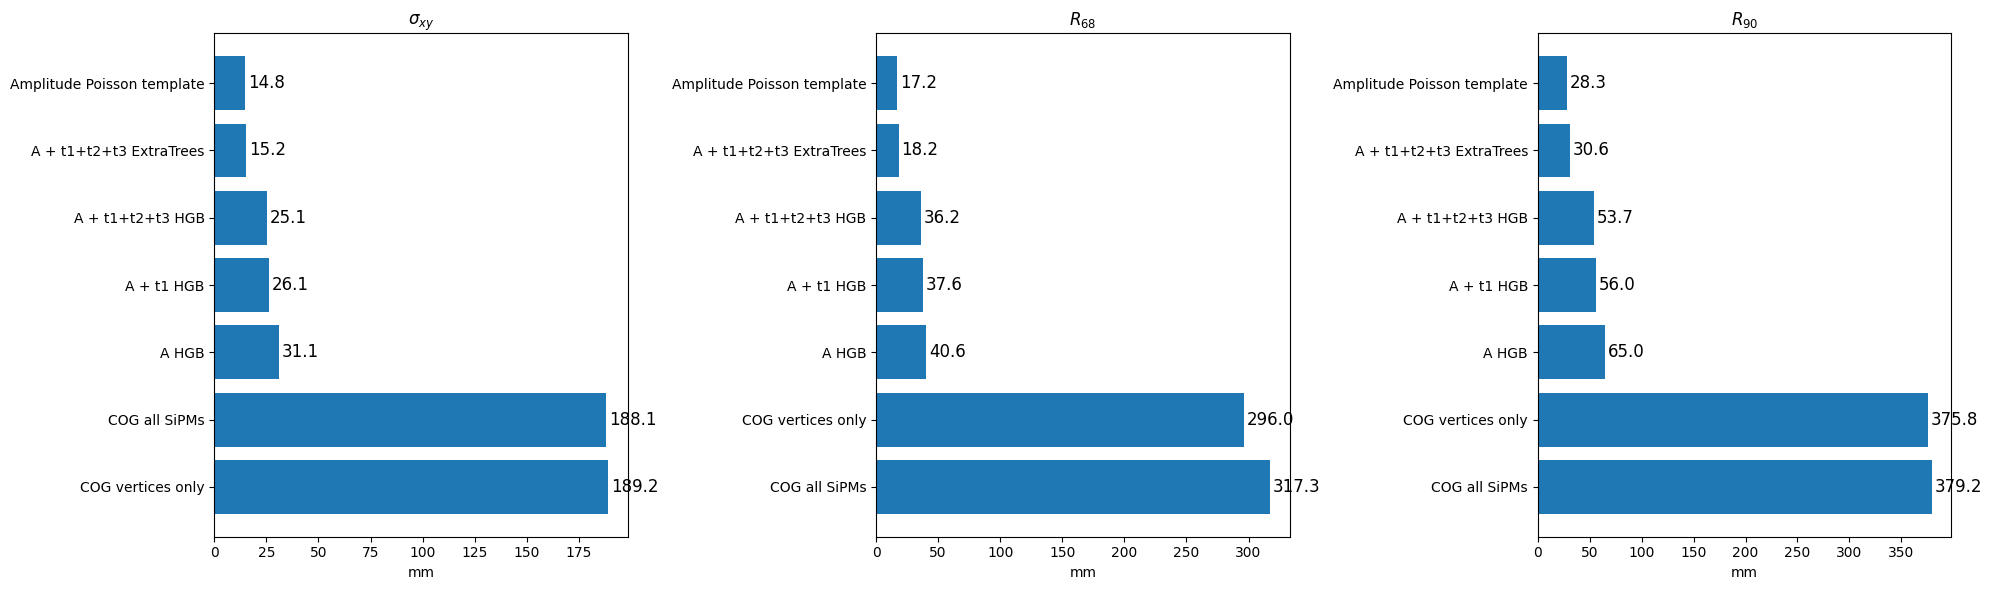

Best by R68: Amplitude Poisson template


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_27723/3744520657.py:43: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax[1,0].hist(dx,100,(-lim,lim),histtype="step",density=True,linewidth=2,
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_27723/3744520657.py:45: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax[1,0].hist(dy,100,(-lim,lim),histtype="step",density=True,linewidth=2,


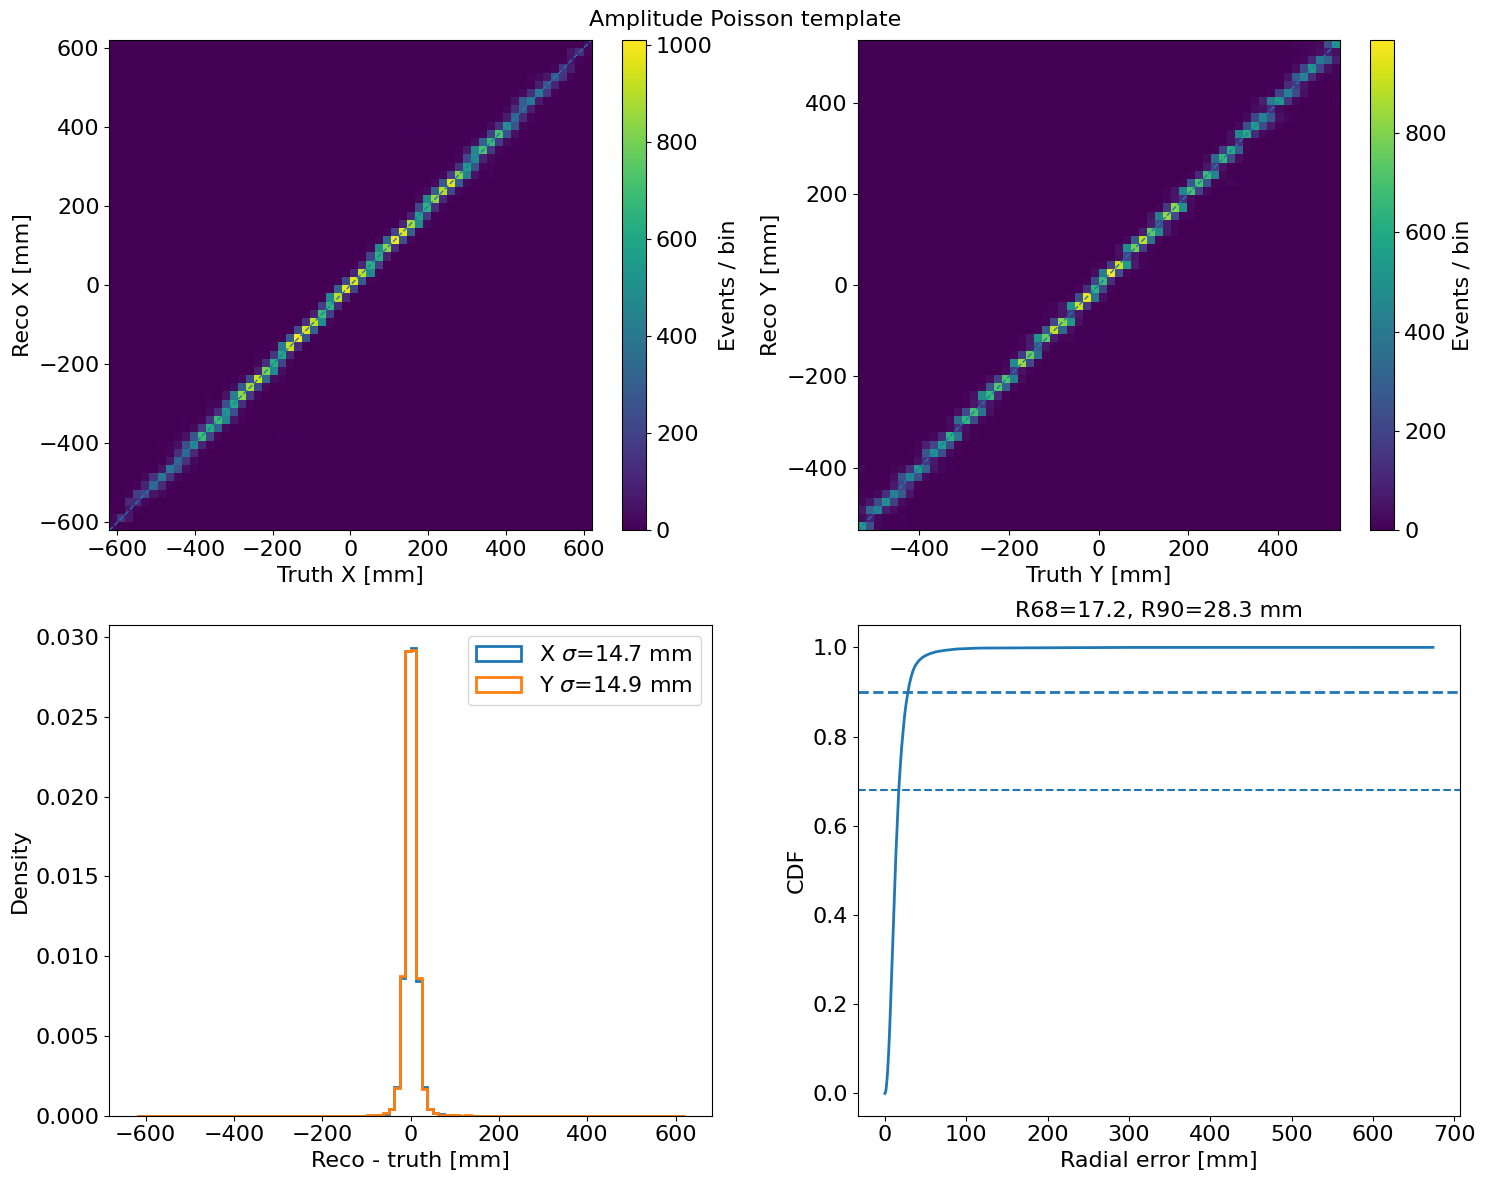

In [124]:

# 11. Summary + comparison
summary=pd.DataFrame([metrics(k,v) for k,v in pred.items()]).sort_values("R68_mm").reset_index(drop=True)
display(summary.round(2))
summary.to_csv(OUT/"spatiotemporal_reconstruction_summary.csv",index=False)

fig,ax=plt.subplots(1,3,figsize=(20,6))
for a,c,t in zip(ax,["sigma_xy_mm","R68_mm","R90_mm"],
                 [r"$\sigma_{xy}$",r"$R_{68}$",r"$R_{90}$"]):
    z=summary.sort_values(c)
    b=a.barh(z.method,z[c])
    a.bar_label(b,fmt="%.1f",padding=2,fontsize=12)
    a.invert_yaxis(); a.set(xlabel="mm",title=t)
plt.tight_layout()
plt.savefig(OUT/"reconstruction_comparison.png",dpi=180,bbox_inches="tight")
plt.show()

best=summary.iloc[0].method
print("Best by R68:",best)
performance(best,pred[best])


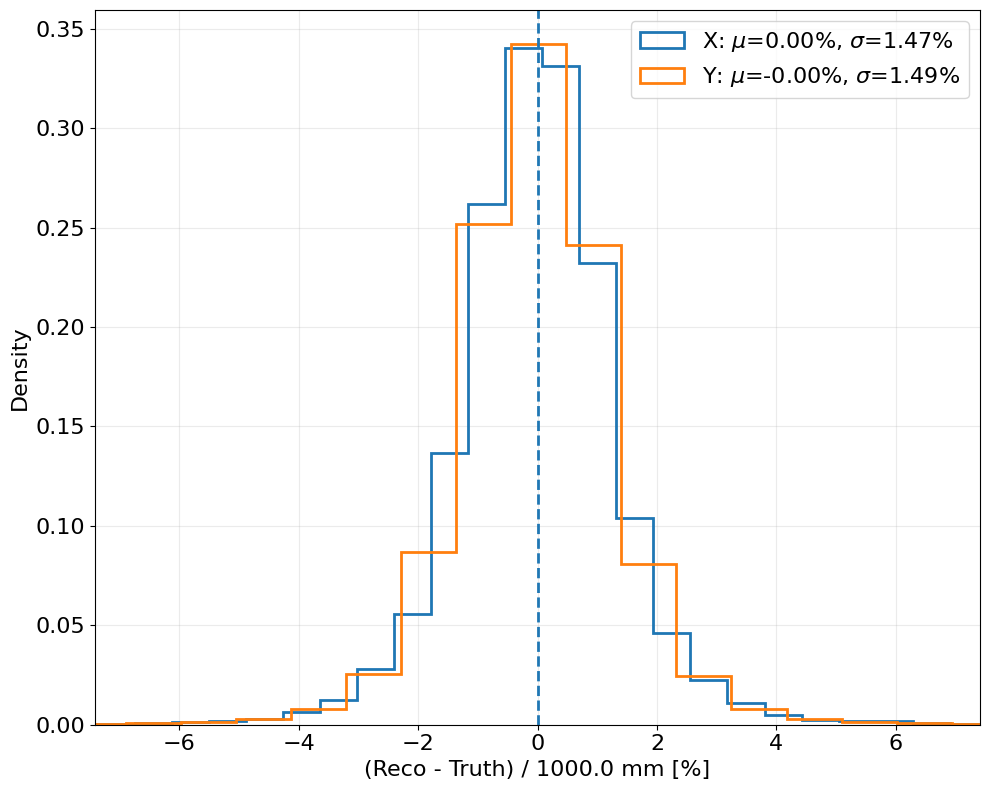

In [125]:
name=best
xy,tru=pred[name],truth[ite]
valid=np.isfinite(xy).all(1)

# Normalize to the side of an equal-area square (~1000 mm for this hexagon).
rel=100*(xy[valid]-tru[valid])/EQUIV_LENGTH
s=max(float(np.sqrt(np.mean(rel.std(0)**2))),1e-6)

fig,ax=plt.subplots(figsize=(10,8))

for j,l in enumerate("XY"):
    r=rel[:,j]
    ax.hist(r,100,histtype="step",density=True,lw=2,
            label=fr"{l}: $\mu$={r.mean():.2f}%, $\sigma$={r.std():.2f}%")

ax.axvline(0,ls="--",lw=2)
ax.set(xlabel=f"(Reco - Truth) / {EQUIV_LENGTH:.1f} mm [%]",
       ylabel="Density",xlim=(-5*s,5*s))
ax.tick_params(labelsize=16)
ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16)
ax.legend(fontsize=16)

plt.tight_layout()
plt.grid(alpha=.25)
plt.savefig(OUT/"resolution_sigmaXY.png",dpi=180,bbox_inches="tight")
plt.show()


## 12. Information-limit check: approximate Poisson CRLB

For independent Poisson observables with expected response $\mu_k(x,y)$,

$$
I_{ab}
=
\sum_k
\frac{1}{\mu_k}
\frac{\partial\mu_k}{\partial a}
\frac{\partial\mu_k}{\partial b},
\qquad a,b\in\{x,y\}.
$$

The inverse Fisher matrix provides a local lower-bound estimate.

This is an **approximate diagnostic**, especially for the timing representation because every event was aligned to its earliest detected photon. It is not a rigorous detector information limit: alignment introduces correlations, and finite calibration statistics can inflate numerical gradients. Use it as a model diagnostic; check calibration-size and grid-size stability before drawing conclusions about a 10 mm target.


Amplitude-only median CRLB sigma_xy: 5.42 mm


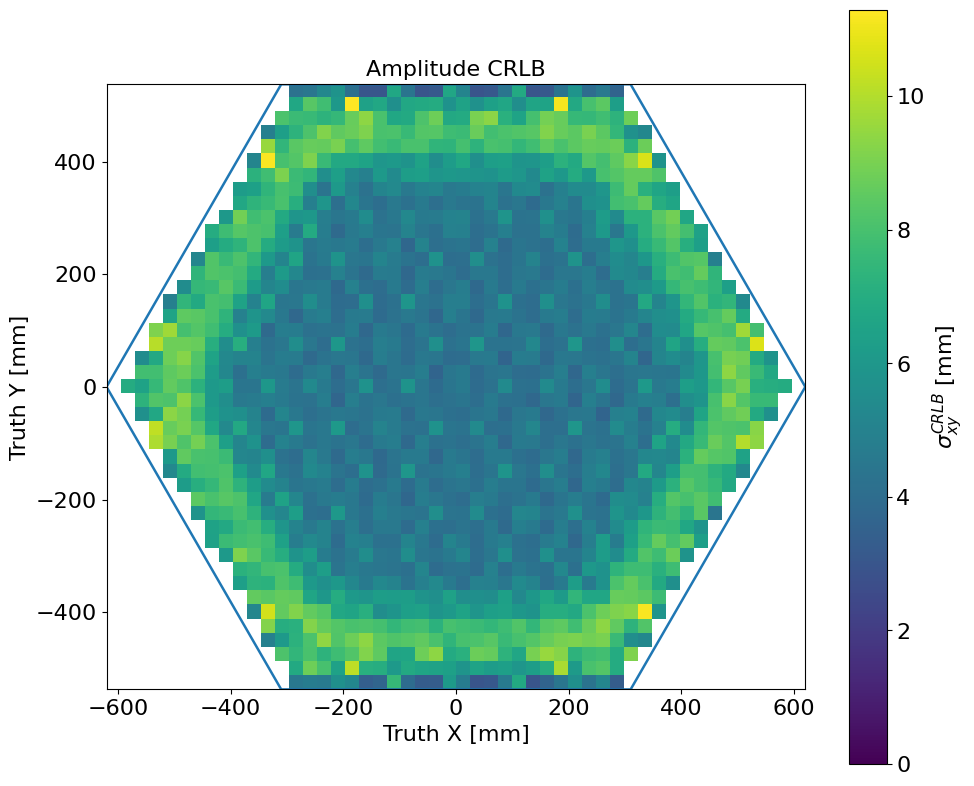

In [126]:
# 12. Approximate CRLB from the regular template grid
def crlb_map(mu_grid,count_grid,mincell=MIN_CELL):
    mu=np.array(mu_grid,float,copy=True)
    valid=(count_grid>=mincell)&np.isfinite(mu).all(2)

    # Exclude grid cells whose centers fall outside the hexagon.
    XX,YY=np.meshgrid(X_CENTERS,Y_CENTERS)
    valid&=inside_hex(XX,YY)
    mu[~valid]=np.nan

    dx=X_CENTERS[1]-X_CENTERS[0]
    dy=Y_CENTERS[1]-Y_CENTERS[0]
    dmy,dmx=np.gradient(mu,dy,dx,axis=(0,1))

    lam=np.clip(mu,1e-6,None)
    Ixx=np.sum(dmx*dmx/lam,axis=2)
    Iyy=np.sum(dmy*dmy/lam,axis=2)
    Ixy=np.sum(dmx*dmy/lam,axis=2)

    det=Ixx*Iyy-Ixy*Ixy
    sx=np.full_like(Ixx,np.nan,float)
    sy=np.full_like(Iyy,np.nan,float)

    complete=np.isfinite(dmx).all(2)&np.isfinite(dmy).all(2)
    m=valid&complete&(Ixx>0)&(Iyy>0)&(det>1e-12*Ixx*Iyy)&np.isfinite(det)
    sx[m]=np.sqrt(Iyy[m]/det[m])
    sy[m]=np.sqrt(Ixx[m]/det[m])
    return sx,sy,np.sqrt((sx*sx+sy*sy)/2)


sxA,syA,sxyA=crlb_map(muAgrid,countA)
print("Amplitude-only median CRLB sigma_xy:",f"{np.nanmedian(sxyA):.2f} mm")

if RUN_FULL_ST:
    sxST,syST,sxyST=crlb_map(muSTgrid,countST)
    print("Full ST median CRLB sigma_xy:",f"{np.nanmedian(sxyST):.2f} mm")
    maps=[(sxyA,"Amplitude CRLB"),(sxyST,"Full spatiotemporal CRLB")]
else:
    maps=[(sxyA,"Amplitude CRLB")]

fig,ax=plt.subplots(1,len(maps),figsize=(10*len(maps),8))
ax=np.atleast_1d(ax)
for a,(z,t) in zip(ax,maps):
    im=a.imshow(z,origin="lower",extent=HEX_EXTENT,aspect="equal",vmin=0)
    draw_hex(a)
    a.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=t)
    a.tick_params(labelsize=16)
    a.xaxis.label.set_size(16); a.yaxis.label.set_size(16); a.title.set_size(16)
    c=plt.colorbar(im,ax=a)
    c.set_label(r"$\sigma_{xy}^{CRLB}$ [mm]",fontsize=16)
    c.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig(OUT/"approximate_CRLB_maps.png",dpi=180,bbox_inches="tight")
plt.show()


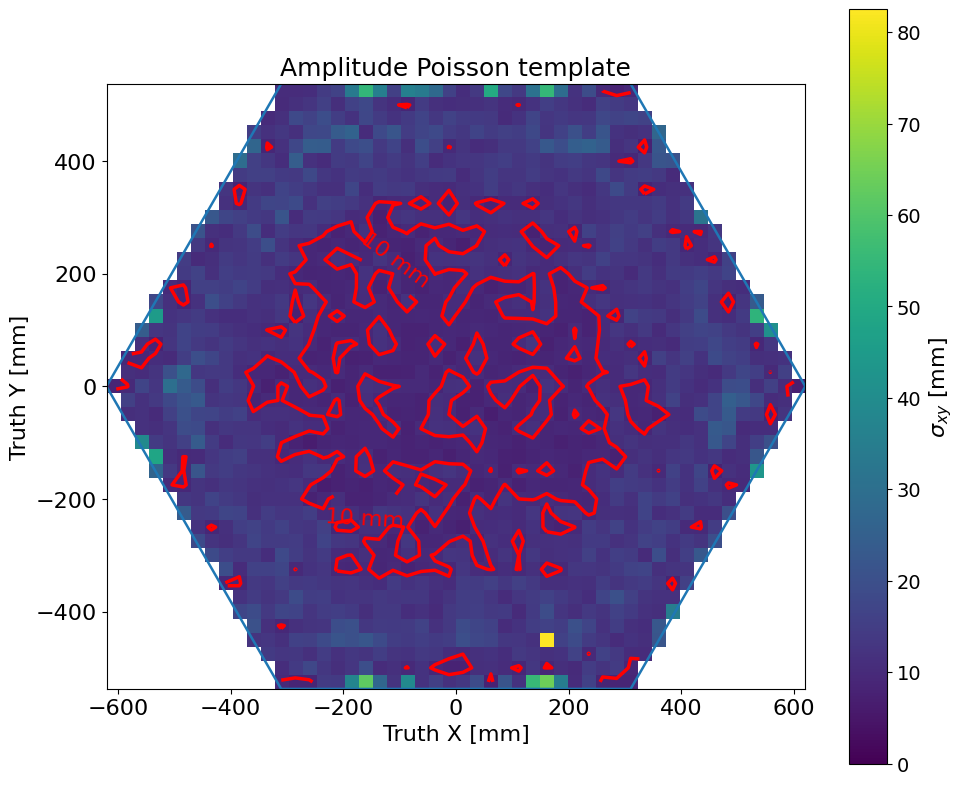

In [127]:
# 12b. Spatial resolution map — best model only
name=best
t,p=truth[ite],pred[name]

def local_error_maps(t,p):
    valid=np.isfinite(p).all(1)
    gid=grid_ids(t[valid]); residual=p[valid]-t[valid]
    counts=np.bincount(gid,minlength=NCELL)
    sums=np.column_stack([np.bincount(gid,weights=residual[:,j],minlength=NCELL) for j in range(2)])
    sums2=np.column_stack([np.bincount(gid,weights=residual[:,j]**2,minlength=NCELL) for j in range(2)])
    mean=np.divide(sums,counts[:,None],out=np.zeros_like(sums),where=counts[:,None]>0)
    second=np.divide(sums2,counts[:,None],out=np.zeros_like(sums2),where=counts[:,None]>0)
    variance=np.maximum(second-mean**2,0)
    maps=[np.sqrt(variance.mean(1)),np.sqrt((mean**2).mean(1)),np.sqrt(second.mean(1))]
    XX,YY=np.meshgrid(X_CENTERS,Y_CENTERS)
    outside=~inside_hex(XX.ravel(),YY.ravel())
    for z in maps:
        z[(counts<MIN_CELL)|outside]=np.nan
    return tuple(z.reshape(GRID_NY,GRID_NX) for z in maps)

sxy,bias,rmse=local_error_maps(t,p)

def contour_10mm(ax,X,Y,z,fontsize):
    finite=z[np.isfinite(z)]
    if len(finite) and finite.min()<10<finite.max():
        cs=ax.contour(X,Y,z,levels=[10],colors="red",linewidths=2.5)
        ax.clabel(cs,fmt="10 mm",fontsize=fontsize)

XX,YY=np.meshgrid(X_CENTERS,Y_CENTERS)

fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(sxy,origin="lower",extent=HEX_EXTENT,aspect="equal",vmin=0)
draw_hex(ax)
contour_10mm(ax,XX,YY,sxy,16)

cbar=plt.colorbar(im,ax=ax)
cbar.set_label(r"$\sigma_{xy}$ [mm]",fontsize=16)
cbar.ax.tick_params(labelsize=14)
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=name)
ax.tick_params(labelsize=16)
ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16); ax.title.set_size(18)
plt.tight_layout()
plt.savefig(OUT/"spatial_resolution_map_best.png",dpi=180,bbox_inches="tight")
plt.show()


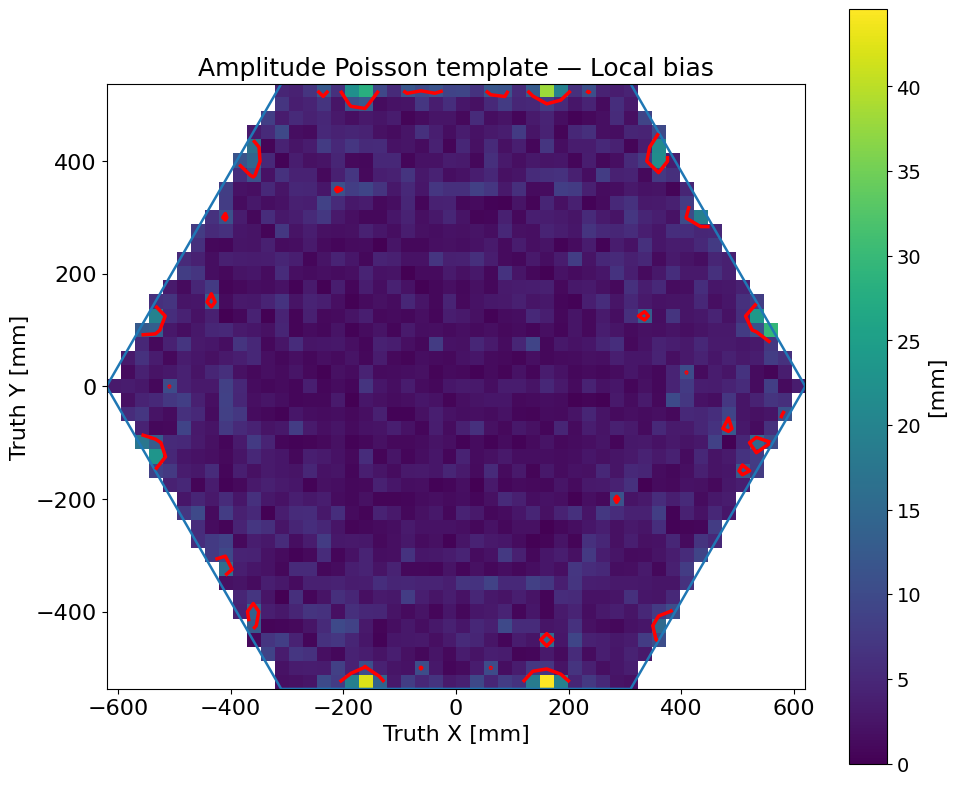

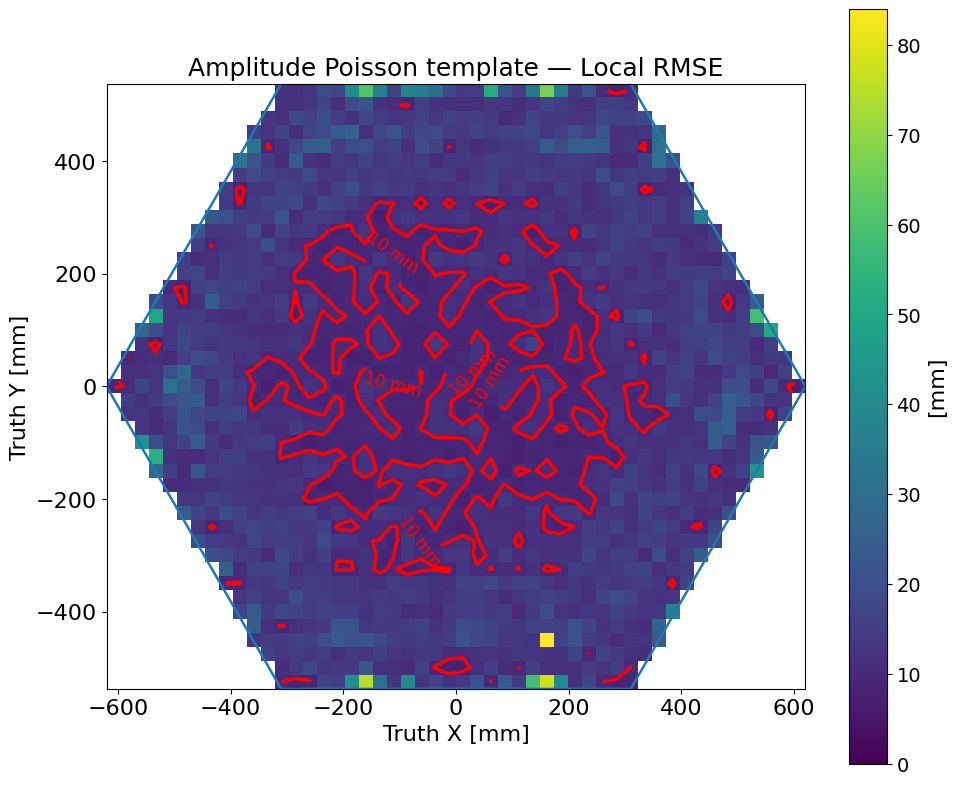

In [128]:
# 12c. Local bias / RMSE maps
for z,title in [(bias,"Local bias"),(rmse,"Local RMSE")]:
    fig,ax=plt.subplots(figsize=(10,8))
    im=ax.imshow(z,origin="lower",extent=HEX_EXTENT,aspect="equal",vmin=0)
    draw_hex(ax)
    contour_10mm(ax,XX,YY,z,12)

    cbar=plt.colorbar(im,ax=ax)
    cbar.set_label("[mm]",fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=f"{name} — {title}")
    ax.tick_params(labelsize=16)
    ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16); ax.title.set_size(18)
    plt.tight_layout()
    plt.show()


## 13. Optional \(dN/dt\) timing-bin scan

The master histogram is 50 ps/bin, so it can be rebinned without re-reading ROOT files.

Recommended factors:

- 1  $\rightarrow$ 50 ps
- 2  $\rightarrow$ 100 ps
- 4  $\rightarrow$ 200 ps
- 6  $\rightarrow$ 300 ps

This directly checks whether the current timing discretization is limiting the reconstruction.


In [129]:
# 13. Optional timing-bin scan using full ST likelihood
if RUN_TIMING_BIN_SCAN and NEED_DND:
    scan=[]
    for fac in [1,2,4,6]:
        if NBIN_FINE%fac: continue

        d=rebin_dnd(DND_FINE,fac)
        if fac==DND_REBIN:
            xy=pred[f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"]
        else:
            k=spatiotemporal_counts(d,A)
            p,m,counts,grid=build_templates(k)
            xy=poisson_reco(k[ite],p,m)
            del k,p,m,counts,grid
        del d
        met=metrics(f"{DT_FINE_NS*fac*1e3:.0f} ps",xy)
        scan.append(met)
        print(met["method"],"R68 =",f'{met["R68_mm"]:.2f} mm')

    scan=pd.DataFrame(scan)
    display(scan.round(2))
    scan.to_csv(OUT/"timing_bin_scan.csv",index=False)

    fig,ax=plt.subplots(figsize=(10,8))
    x=scan.method.str.replace(" ps","",regex=False).astype(float)
    ax.plot(x,scan.R68_mm,"o-",label=r"$R_{68}$")
    ax.plot(x,scan.sigma_xy_mm,"s-",label=r"$\sigma_{xy}$")
    ax.set(xlabel=r"$dN/dt$ bin width [ps]",ylabel="Position resolution [mm]")
    ax.tick_params(labelsize=15)
    ax.title.set_size(15)
    ax.xaxis.label.set_size(15)
    ax.yaxis.label.set_size(15)
    ax.grid(alpha=.25); ax.legend(fontsize=15)
    plt.savefig(OUT/"timing_bin_scan.png",dpi=180,bbox_inches="tight")
    plt.show()
else:
    print("RUN_TIMING_BIN_SCAN=False -> skipped")


RUN_TIMING_BIN_SCAN=False -> skipped


# How to interpret the result

The most important progression is

$$
A
\rightarrow
A+t_1
\rightarrow
A+t_1+t_2+t_3
\rightarrow
A+dN/dt
\rightarrow
L_{\rm full\,ST}.
$$

Typical interpretations:

- **\(A+t_1\) improves strongly over amplitude**: propagation timing carries independent position information.
- **\(t_2,t_3\) add further improvement**: the early-photon order statistics are useful beyond the first photon.
- **\(dN/dt\) improves further**: waveform/arrival-time shape contains information that simple timing summaries discard.
- **Full ST likelihood improves over regression**: the detector response is well described by the calibrated photon space-time templates.
- **Approximate CRLB far above or below 10 mm**: investigate response-model assumptions, calibration statistics and grid-size stability before inferring detector limits or algorithmic headroom.


# 14. True detector timing-resolution scan
This scan is different from the \(dN/dt\) bin-width scan above.
For every detected photon, apply an independent Gaussian timestamp jitter
$$
t_{\rm meas}=t_{\rm Geant4}+\mathcal N(0,\sigma_t),
$$ where sigma_t is the assumed single-photon detector timing resolution.

$$
t_{\rm hit}^{\rm Geant4}
\rightarrow
t_{\rm hit}^{\rm smeared}
\rightarrow
t_0
\rightarrow
\Delta t
\rightarrow
t_1,t_2,t_3
\rightarrow
\text{ExtraTrees}$$

After smearing, both the event-wide reference time
$$
t_0=\min(t_{\rm meas})
$$ and the first/second/third photon ordering are recalculated. The amplitude information is unchanged.
Therefore this directly tests how the A + t1+t2+t3 ExtraTrees position resolution degrades as the detector timing resolution becomes worse.


In [130]:
# 14. Reuse exactly the same validated timing extraction as the main study
def smeared_T123(sigma_ps,seed=SEED+100):
    if sigma_ps<0: raise ValueError("Timing sigma must be nonnegative")
    rg=np.random.default_rng(seed)
    times=[np.full((len(good),NSIPM),np.nan,np.float32) for _ in range(3)]
    offset=0
    for fname in FILES:
        with uproot.open(fname) as f:
            et=f["events"]
            ev=integer_ids(et["event"].array(library="np") if "event" in et.keys()
                           else np.arange(et.num_entries),"events.event")
            row,sipm,tm=read_hit_arrays(f,ev)
            values=timing_features(row,sipm,tm,len(ev),sigma_ps,rg,with_dnd=False)
        for target,value in zip(times,values[:3]): target[offset:offset+len(ev)]=value
        offset+=len(ev)
    if offset!=len(good): raise ValueError("Input event count changed after loading")
    return tuple(t[good] for t in times)

if RUN_TRUE_TIMING_SCAN:
    scan_true=[]

    for sig in SIGMA_T_PS:
        t1,t2,t3=smeared_T123(sig)

        X=np.hstack([Afeat,t1,t2,t3])
        med=training_medians(X[itr_ml])
        X=np.where(np.isfinite(X),X,med)

        model=ExtraTreesRegressor(
            n_estimators=300,min_samples_leaf=2,max_features=.8,
            n_jobs=-1,random_state=SEED
        )
        model.fit(X[itr_ml],truth[itr_ml])
        xy=model.predict(X[ite])
        del model,X,t1,t2,t3

        m=metrics(f"{sig} ps",xy)
        m["sigma_t_ps"]=sig
        scan_true.append(m)

        print(f'{sig:4d} ps: sigma_xy={m["sigma_xy_mm"]:.2f} mm, '
              f'R68={m["R68_mm"]:.2f} mm')

    scan_true=pd.DataFrame(scan_true)
    display(scan_true[["sigma_t_ps","sigma_xy_mm","R68_mm","R90_mm"]].round(2))
    scan_true.to_csv(OUT/"true_detector_timing_resolution_scan.csv",index=False)

    fig,ax=plt.subplots(figsize=(10,8))

    ax.plot(scan_true.sigma_t_ps,scan_true.R68_mm,"o-",label=r"$R_{68}$")
    ax.plot(scan_true.sigma_t_ps,scan_true.sigma_xy_mm,"s-",label=r"$\sigma_{xy}$")

    for x,y in zip(scan_true.sigma_t_ps,scan_true.R68_mm):
        ax.annotate(f"{y:.1f}",(x,y),xytext=(0,8),
                    textcoords="offset points",ha="center",fontsize=13)

    for x,y in zip(scan_true.sigma_t_ps,scan_true.sigma_xy_mm):
        ax.annotate(f"{y:.1f}",(x,y),xytext=(0,-16),
                    textcoords="offset points",ha="center",fontsize=13)

    ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
        ylabel="Position resolution [mm]")
    ax.tick_params(labelsize=15)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
    ax.grid(alpha=.25); ax.legend(fontsize=15)

    plt.tight_layout()
    plt.savefig(OUT/"true_detector_timing_resolution_scan.png",
                dpi=180,bbox_inches="tight")
    plt.show()

    scan_true["R68_pct"]=100*scan_true.R68_mm/EQUIV_LENGTH
    scan_true["sigma_pct"]=100*scan_true.sigma_xy_mm/EQUIV_LENGTH
    fig,ax=plt.subplots(figsize=(10,8))
    ax.plot(scan_true.sigma_t_ps,scan_true.R68_pct,"o-",label=r"$R_{68}$")
    ax.plot(scan_true.sigma_t_ps,scan_true.sigma_pct,"s-",label=r"$\sigma_{xy}$")
    for x,y in zip(scan_true.sigma_t_ps,scan_true.R68_pct):
        ax.annotate(f"{y:.2f}",(x,y),xytext=(0,8),
                    textcoords="offset points",ha="center",fontsize=13)
    for x,y in zip(scan_true.sigma_t_ps,scan_true.sigma_pct):
        ax.annotate(f"{y:.2f}",(x,y),xytext=(0,-16),
                    textcoords="offset points",ha="center",fontsize=13)
    ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
        ylabel=f"Position resolution / {EQUIV_LENGTH:.1f} mm [%]")
    ax.tick_params(labelsize=15)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
    ax.grid(alpha=.25); ax.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig(OUT/"true_detector_timing_resolution_relative.png",
                dpi=180,bbox_inches="tight")
    plt.show()
else:
    print("RUN_TRUE_TIMING_SCAN=False -> skipped")


RUN_TRUE_TIMING_SCAN=False -> skipped


# 15. Compare all division/ring productions

After running the reconstruction cells once for each `SETUP`, this cell collects the saved
`A + t1+t2+t3 ExtraTrees` result and compares the common resolution metrics versus the total number of SiPM channels.

This is the main plot for the geometry/channel-count scan.


,tag,channels,sigma_xy_mm,R68_mm,R90_mm,sigma_x_mm,sigma_y_mm
0,edge3_center6,37,23.94,31.92,49.95,23.95,23.93
1,edge2_ring2_p207,37,24.75,32.88,52.06,24.92,24.58
2,edge3_ring2_p207,43,22.19,29.47,46.14,22.16,22.21
3,edge3_ring3_p140,61,19.02,24.27,38.85,19.05,18.99
4,edge3_ring4_p105,85,17.69,21.52,36.30,17.61,17.76
5,edge3_ring5_p84,115,17.09,19.92,35.54,17.22,16.96
6,edge5_ring5_p84,127,15.18,18.18,30.61,15.21,15.15


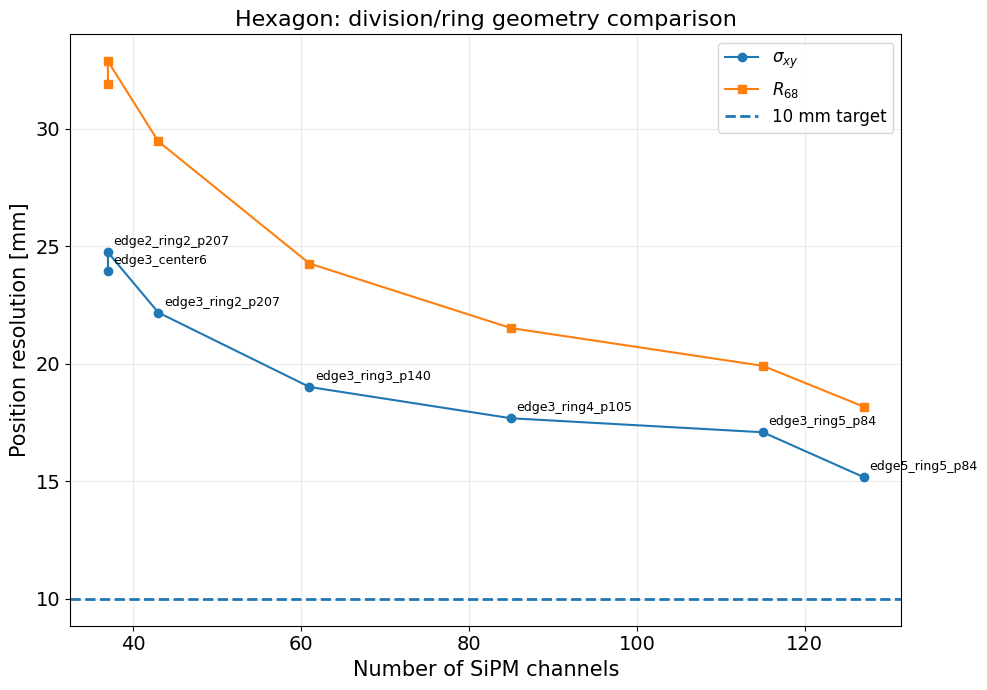

In [131]:
# 15. Multi-setup comparison from saved summaries
METHOD="A + t1+t2+t3 ExtraTrees"
rows=[]

for tag,c in SETUPS.items():
    mode=c["mode"]; edge=c["edge"]
    center=(division_count(c.get("center",0)) if mode=="division"
            else 1+3*c["rings"]*(c["rings"]+1))
    nch=6+6*edge+center
    fn=RUN/f"output_{tag}_reco"/"spatiotemporal_reconstruction_summary.csv"

    if not fn.exists():
        print("Missing:",fn)
        continue

    df=pd.read_csv(fn)
    hit=df[df["method"]==METHOD]
    if hit.empty:
        print(f"{tag}: {METHOD} not found")
        continue

    r=hit.iloc[0].to_dict()
    r.update(tag=tag,mode=mode,channels=nch,edge=edge,center=center,
             rings=c.get("rings",np.nan),pitch_mm=c.get("pitch",np.nan))
    rows.append(r)

comparison=pd.DataFrame(rows).sort_values("channels").reset_index(drop=True)
display(comparison[["tag","channels","sigma_xy_mm","R68_mm","R90_mm",
                    "sigma_x_mm","sigma_y_mm"]].round(2))

if len(comparison):
    comparison.to_csv(RUN/"ring_geometry_resolution_comparison.csv",index=False)

    fig,ax=plt.subplots(figsize=(10,7))
    ax.plot(comparison.channels,comparison.sigma_xy_mm,"o-",label=r"$\sigma_{xy}$")
    ax.plot(comparison.channels,comparison.R68_mm,"s-",label=r"$R_{68}$")
    ax.axhline(10,ls="--",lw=2,label="10 mm target")

    for _,r in comparison.iterrows():
        ax.annotate(r["tag"],(r.channels,r.sigma_xy_mm),
                    xytext=(4,5),textcoords="offset points",fontsize=9)

    ax.set(xlabel="Number of SiPM channels",ylabel="Position resolution [mm]",
           title="Hexagon: division/ring geometry comparison")
    ax.tick_params(labelsize=14)
    ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15); ax.title.set_size(16)
    ax.grid(alpha=.25); ax.legend(fontsize=12)
    plt.tight_layout()
    plt.savefig(RUN/"ring_geometry_resolution_vs_channels.png",dpi=180,bbox_inches="tight")
    plt.show()
